## Data Selection            


In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from colorama import Fore, Style
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier

# Membaca dataset dari file Excel
file_path = "Dataset.xlsx"
df = pd.read_excel(file_path)

# Menampilkan 5 baris pertama untuk melihat struktur data
print("Lima Baris Pertama Dataset:")
print(df.head())

# Menampilkan informasi dataset (jumlah baris, tipe data, dan nilai null)
print("\nInformasi Dataset:")
print(df.info())

# Menampilkan ringkasan statistik dari dataset
print("\nRingkasan Statistik Dataset:")
print(df.describe(include="all"))

# Memilih variabel yang relevan (Pastikan semua kolom yang digunakan)
selected_columns = [
    "Model motor", "Tahun", "Mesin", "Kilometer (Jarak tempuh)",
    "Bahan Bakar", "Modifikasi", "Turun mesin", "Jenis oli",
    "Tranmisi", "Jenis mesin", "Kubikasi", "Keputusan"
]

df_selected = df[selected_columns]

# Menampilkan 5 baris pertama dari dataset yang telah dipilih
print("\nLima Baris Pertama Dataset Setelah Seleksi:")
print(df_selected.head())


Lima Baris Pertama Dataset:
        Model motor  Tahun  Mesin  Kilometer (Jarak tempuh) Bahan Bakar  \
0   Honda Vario 160   2022  Halus                    354090    Pertamax   
1        Honda BeAT   2014  Kasar                    377020   Pertalite   
2      Honda Scoopy   2010  Halus                    325890   Pertalite   
3  Honda Vario 110    2009  Kasar                    557342   Pertalite   
4   Honda Vario 125   2012  Halus                    478920   Pertalite   

  Modifikasi Turun mesin         Jenis oli  Tranmisi Jenis mesin  Kubikasi  \
0     Ringan       Tidak  Federal Ultratec  Otomatis       4-Tak       160   
1     Sedang         Iya          AHM SPX1  Otomatis       4-Tak       108   
2     Sedang         Iya    Castrol Power1  Otomatis       4-Tak       108   
3     Sedang       Tidak          AHM SPX1  Otomatis       4-Tak       108   
4      Berat         Iya          AHM SPX1  Otomatis       4-Tak       125   

      Keputusan  
0  Layak dijual  
1   Tidak layak 

##  Preprocessing

In [41]:
# 1. Menghapus duplikasi data jika ada
df_selected = df[selected_columns].drop_duplicates()
print(f"Jumlah data setelah menghapus duplikasi: {df_selected.shape[0]} baris")

# 2. Menangani data kosong (mengisi dengan modus untuk kategorikal, median untuk numerik)
for col in df_selected.columns:
    if df_selected[col].dtype == "object":  # Jika kolom kategorikal
        df_selected[col] = df_selected[col].fillna(df_selected[col].mode()[0])
    else:  # Jika kolom numerik
        df_selected[col] = df_selected[col].fillna(df_selected[col].median())

# 3. Mengonversi data kategorikal menjadi numerik menggunakan Label Encoding
from sklearn.preprocessing import LabelEncoder

label_encoders = {}  # Dictionary untuk menyimpan encoder setiap kolom kategorikal
for col in df_selected.select_dtypes(include=["object"]).columns:
    le = LabelEncoder()
    df_selected[col] = le.fit_transform(df_selected[col])
    label_encoders[col] = le  # Simpan encoder untuk referensi

# Menampilkan dataset setelah preprocessing
print("\nDataset setelah preprocessing:")
print(df_selected.head())

# Menampilkan jumlah nilai null setelah preprocessing
print("\nJumlah nilai null setelah preprocessing:")
print(df_selected.isnull().sum())


Jumlah data setelah menghapus duplikasi: 145 baris

Dataset setelah preprocessing:
   Model motor  Tahun  Mesin  Kilometer (Jarak tempuh)  Bahan Bakar  \
0           30   2022      0                    354090            1   
1            0   2014      1                    377020            0   
2           15   2010      0                    325890            0   
3           26   2009      1                    557342            0   
4           27   2012      0                    478920            0   

   Modifikasi  Turun mesin  Jenis oli  Tranmisi  Jenis mesin  Kubikasi  \
0           1            1          7         1            0       160   
1           2            0          0         1            0       108   
2           2            0          5         1            0       108   
3           2            1          0         1            0       108   
4           0            0          0         1            0       125   

   Keputusan  
0          0  
1          1  


## Transformation

In [42]:
from sklearn.preprocessing import MinMaxScaler

# 1. Menentukan kolom numerik yang akan dinormalisasi
numerical_columns = ["Tahun", "Mesin", "Kilometer (Jarak tempuh)", "Kubikasi"]  # Sesuai dengan dataset

# 2. Inisialisasi MinMaxScaler
scaler = MinMaxScaler()

# 3. Melakukan normalisasi pada kolom numerik
df_selected[numerical_columns] = scaler.fit_transform(df_selected[numerical_columns])

# Menampilkan dataset setelah normalisasi
print("\nDataset setelah normalisasi:")
print(df_selected.head())

# Menampilkan range minimum dan maksimum setelah normalisasi
print("\nRange nilai setelah normalisasi:")
print(df_selected[numerical_columns].describe())



Dataset setelah normalisasi:
   Model motor     Tahun  Mesin  Kilometer (Jarak tempuh)  Bahan Bakar  \
0           30  0.866667    0.0                  0.567287            1   
1            0  0.333333    1.0                  0.608167            0   
2           15  0.066667    0.0                  0.517011            0   
3           26  0.000000    1.0                  0.929651            0   
4           27  0.200000    0.0                  0.789838            0   

   Modifikasi  Turun mesin  Jenis oli  Tranmisi  Jenis mesin  Kubikasi  \
0           1            1          7         1            0  1.000000   
1           2            0          0         1            0  0.000000   
2           2            0          5         1            0  0.000000   
3           2            1          0         1            0  0.000000   
4           0            0          0         1            0  0.326923   

   Keputusan  
0          0  
1          1  
2          1  
3          1  
4    

## Data Mining (Implementasi Algoritma C4.5)


In [43]:
# Pastikan kolom target "Keputusan" ada
if 'Keputusan' not in df_selected.columns:
    raise ValueError("Kolom 'Keputusan' tidak ditemukan dalam dataset!")

# Definisikan variabel y sebagai kolom target
y = df_selected['Keputusan']

# Fungsi untuk menghitung entropy
def calculate_entropy(y):
    if len(y) == 0:
        return 0

    # Menghitung proporsi setiap kelas
    classes, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    # Menghitung entropy menggunakan rumus: -sum(p * log2(p))
    entropy = -np.sum(probabilities * np.log2(probabilities))
    return entropy

# Menghitung entropy dataset awal
entropy_total = calculate_entropy(y)
print(f"Entropy Total Dataset: {entropy_total:.4f}")

Entropy Total Dataset: 0.9784



=== Feature Importance ===
                       Fitur  Importance
3   Kilometer (Jarak tempuh)    0.438905
1                      Tahun    0.192326
0                Model motor    0.139539
7                  Jenis oli    0.063271
2                      Mesin    0.062371
6                Turun mesin    0.043667
5                 Modifikasi    0.037439
10                  Kubikasi    0.014410
4                Bahan Bakar    0.008072
8                   Tranmisi    0.000000
9                Jenis mesin    0.000000


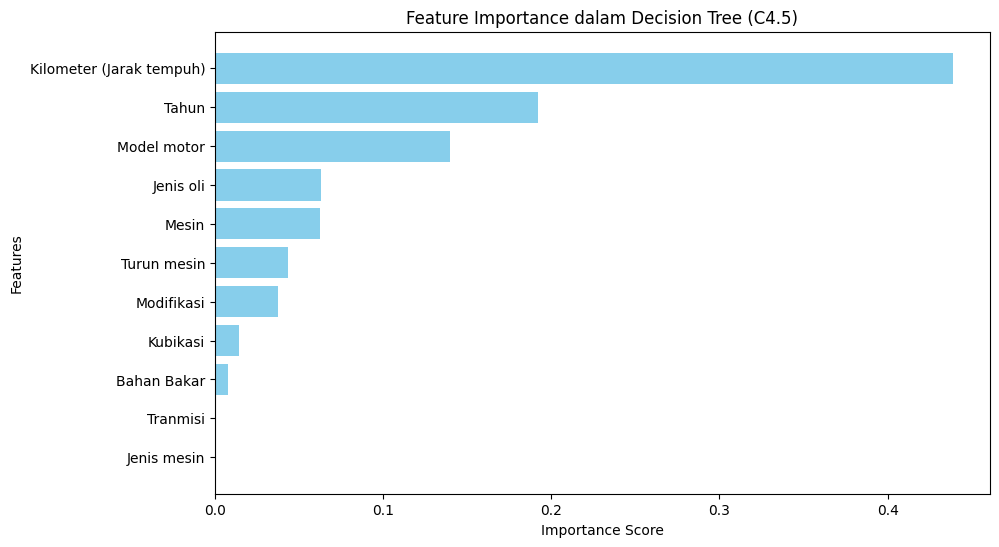

In [44]:
# Pastikan dataset sudah ada
if 'Keputusan' not in df_selected.columns:
    raise ValueError("Kolom 'Keputusan' tidak ditemukan dalam dataset!")

# Definisikan variabel fitur (X) dan target (y)
X = df_selected.drop(columns=['Keputusan'])  # Fitur (independent variables)
y = df_selected['Keputusan']  # Target (dependent variable)

# Buat model Decision Tree (C4.5 menggunakan entropy)
clf = DecisionTreeClassifier(criterion="entropy")
clf.fit(X, y)  # Melatih model

# === Menampilkan Feature Importance dalam Bentuk Tabel dan ASCII Chart ===
feature_importance = pd.DataFrame({"Fitur": X.columns, "Importance": clf.feature_importances_})
feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print(Fore.MAGENTA + "\n=== Feature Importance ===" + Style.RESET_ALL)
print(feature_importance)

# === Visualisasi Feature Importance dengan Matplotlib ===
plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Fitur"], feature_importance["Importance"], color="skyblue")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance dalam Decision Tree (C4.5)")
plt.gca().invert_yaxis()  # Membalik urutan fitur agar yang paling penting ada di atas
plt.show()

In [45]:
from colorama import Fore, Style

def calculate_entropy(y):
    """Menghitung entropy dari label target y."""
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return -np.sum(probabilities * np.log2(probabilities))

def calculate_gain_ratio(X, y, feature):
    entropy_before = calculate_entropy(y)

    values = X[feature].unique()
    weighted_entropy = 0
    split_info = 0

    for value in values:
        subset_indices = X[feature] == value
        subset_size = subset_indices.sum()

        if subset_size > 0:
            proportion = subset_size / len(y)
            subset_entropy = calculate_entropy(y[subset_indices])
            weighted_entropy += proportion * subset_entropy
            split_info -= proportion * np.log2(proportion)

    information_gain = entropy_before - weighted_entropy
    gain_ratio = information_gain / split_info if split_info != 0 else 0

    return information_gain, gain_ratio, split_info

# Menampilkan header yang menarik
print(Fore.CYAN + "\n=== Perhitungan Gain Ratio C4.5 ===\n" + Style.RESET_ALL)

gain_ratios = {}
information_gains = {}
split_infos = {}

# Iterasi untuk setiap fitur dalam dataset
results = []
for feature in X.columns:
    info_gain, gain_ratio, split_info = calculate_gain_ratio(X, y, feature)
    information_gains[feature] = info_gain
    gain_ratios[feature] = gain_ratio
    split_infos[feature] = split_info
    results.append([feature, info_gain, split_info, gain_ratio])

# Menampilkan hasil dalam bentuk tabel
df_results = pd.DataFrame(results, columns=["Fitur", "Information Gain", "Split Info", "Gain Ratio"])
df_results = df_results.sort_values(by="Gain Ratio", ascending=False)

print(df_results.to_string(index=False, float_format="%.4f"))

# Menampilkan fitur terbaik dengan efek warna
best_feature = df_results.iloc[0]["Fitur"]
best_gain_ratio = df_results.iloc[0]["Gain Ratio"]

print(Fore.GREEN + f"\nFitur terbaik untuk root node: {best_feature} (Gain Ratio: {best_gain_ratio:.4f})" + Style.RESET_ALL)



=== Perhitungan Gain Ratio C4.5 ===

                   Fitur  Information Gain  Split Info  Gain Ratio
Kilometer (Jarak tempuh)            0.9784      7.1799      0.1363
             Model motor            0.4485      5.2028      0.0862
               Jenis oli            0.0873      2.2830      0.0382
                   Tahun            0.1322      3.5679      0.0371
              Modifikasi            0.0514      1.4859      0.0346
                Kubikasi            0.0845      2.4491      0.0345
                Tranmisi            0.0052      0.5214      0.0100
             Bahan Bakar            0.0025      0.8400      0.0030
                   Mesin            0.0023      0.9991      0.0023
             Turun mesin            0.0000      0.9972      0.0000
             Jenis mesin            0.0000      0.0000      0.0000

Fitur terbaik untuk root node: Kilometer (Jarak tempuh) (Gain Ratio: 0.1363)


In [46]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split

# 1. Memisahkan fitur (X) dan label (y)
X = df_selected.drop(columns=["Keputusan"])  # Semua kolom kecuali target
y = df_selected["Keputusan"]  # Kolom target

# 2. Membagi data menjadi Training (80%) dan Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Membuat model Decision Tree (C4.5) dengan Entropy sebagai criterion
clf = DecisionTreeClassifier(criterion="entropy", random_state=72)

# 4. Melatih model dengan data training
clf.fit(X_train, y_train)

# 5. Mencetak aturan keputusan dalam bentuk teks
tree_rules = export_text(clf, feature_names=list(X.columns))
print("\nAturan Keputusan dari Decision Tree (C4.5):")
print(tree_rules)



Aturan Keputusan dari Decision Tree (C4.5):
|--- Tahun <= 0.83
|   |--- Kubikasi <= 0.09
|   |   |--- Kilometer (Jarak tempuh) <= 0.51
|   |   |   |--- Model motor <= 10.50
|   |   |   |   |--- Model motor <= 1.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Model motor >  1.50
|   |   |   |   |   |--- Model motor <= 2.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- Model motor >  2.50
|   |   |   |   |   |   |--- Model motor <= 7.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- Model motor >  7.50
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |--- Model motor >  10.50
|   |   |   |   |--- class: 0
|   |   |--- Kilometer (Jarak tempuh) >  0.51
|   |   |   |--- Model motor <= 1.50
|   |   |   |   |--- Kilometer (Jarak tempuh) <= 0.54
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Kilometer (Jarak tempuh) >  0.54
|   |   |   |   |   |--- Kilometer (Jarak tempuh) <= 0.83
|   |   |   |   |   |   |--- Mesin <= 0.50
|   | 

## Visualisasi

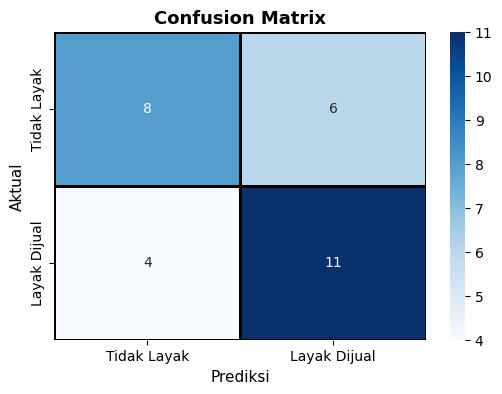

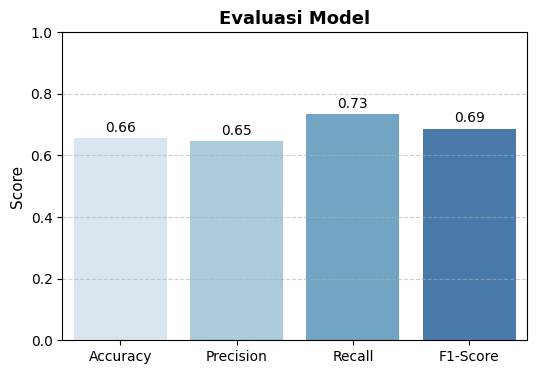


Evaluasi Model Decision Tree
Akurasi    : 0.6552
Precision  : 0.6471
Recall     : 0.7333
F1-Score   : 0.6875

Classification Report:
              precision    recall  f1-score   support

 Tidak Layak       0.67      0.57      0.62        14
Layak Dijual       0.65      0.73      0.69        15

    accuracy                           0.66        29
   macro avg       0.66      0.65      0.65        29
weighted avg       0.66      0.66      0.65        29



In [47]:
# Membagi dataset menjadi training & testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Melatih model Decision Tree
clf = DecisionTreeClassifier(criterion="entropy")
clf.fit(X_train, y_train)

# 1️⃣ Prediksi data uji
y_pred = clf.predict(X_test)

# 2️⃣ Membuat Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 3️⃣ Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='black',
            xticklabels=["Tidak Layak", "Layak Dijual"],
            yticklabels=["Tidak Layak", "Layak Dijual"])

plt.xlabel("Prediksi", fontsize=11)
plt.ylabel("Aktual", fontsize=11)
plt.title("Confusion Matrix", fontsize=13, fontweight="bold")
plt.show()

# 4️⃣ Menghitung Metrik Evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='binary')
recall = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')

# 5️⃣ Menampilkan Bar Chart Evaluasi Model
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(6, 4))
sns.barplot(x=metrics, y=values, hue=metrics, palette="Blues", alpha=0.85, legend=False)

plt.ylim(0, 1)
plt.ylabel("Score", fontsize=11)
plt.title("Evaluasi Model", fontsize=13, fontweight="bold")

# Tambahkan nilai di atas setiap batang
for i, v in enumerate(values):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# 6️⃣ Menampilkan Hasil Evaluasi
print("\nEvaluasi Model Decision Tree")
print(f"Akurasi    : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")

# 7️⃣ Laporan Klasifikasi
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Tidak Layak", "Layak Dijual"]))

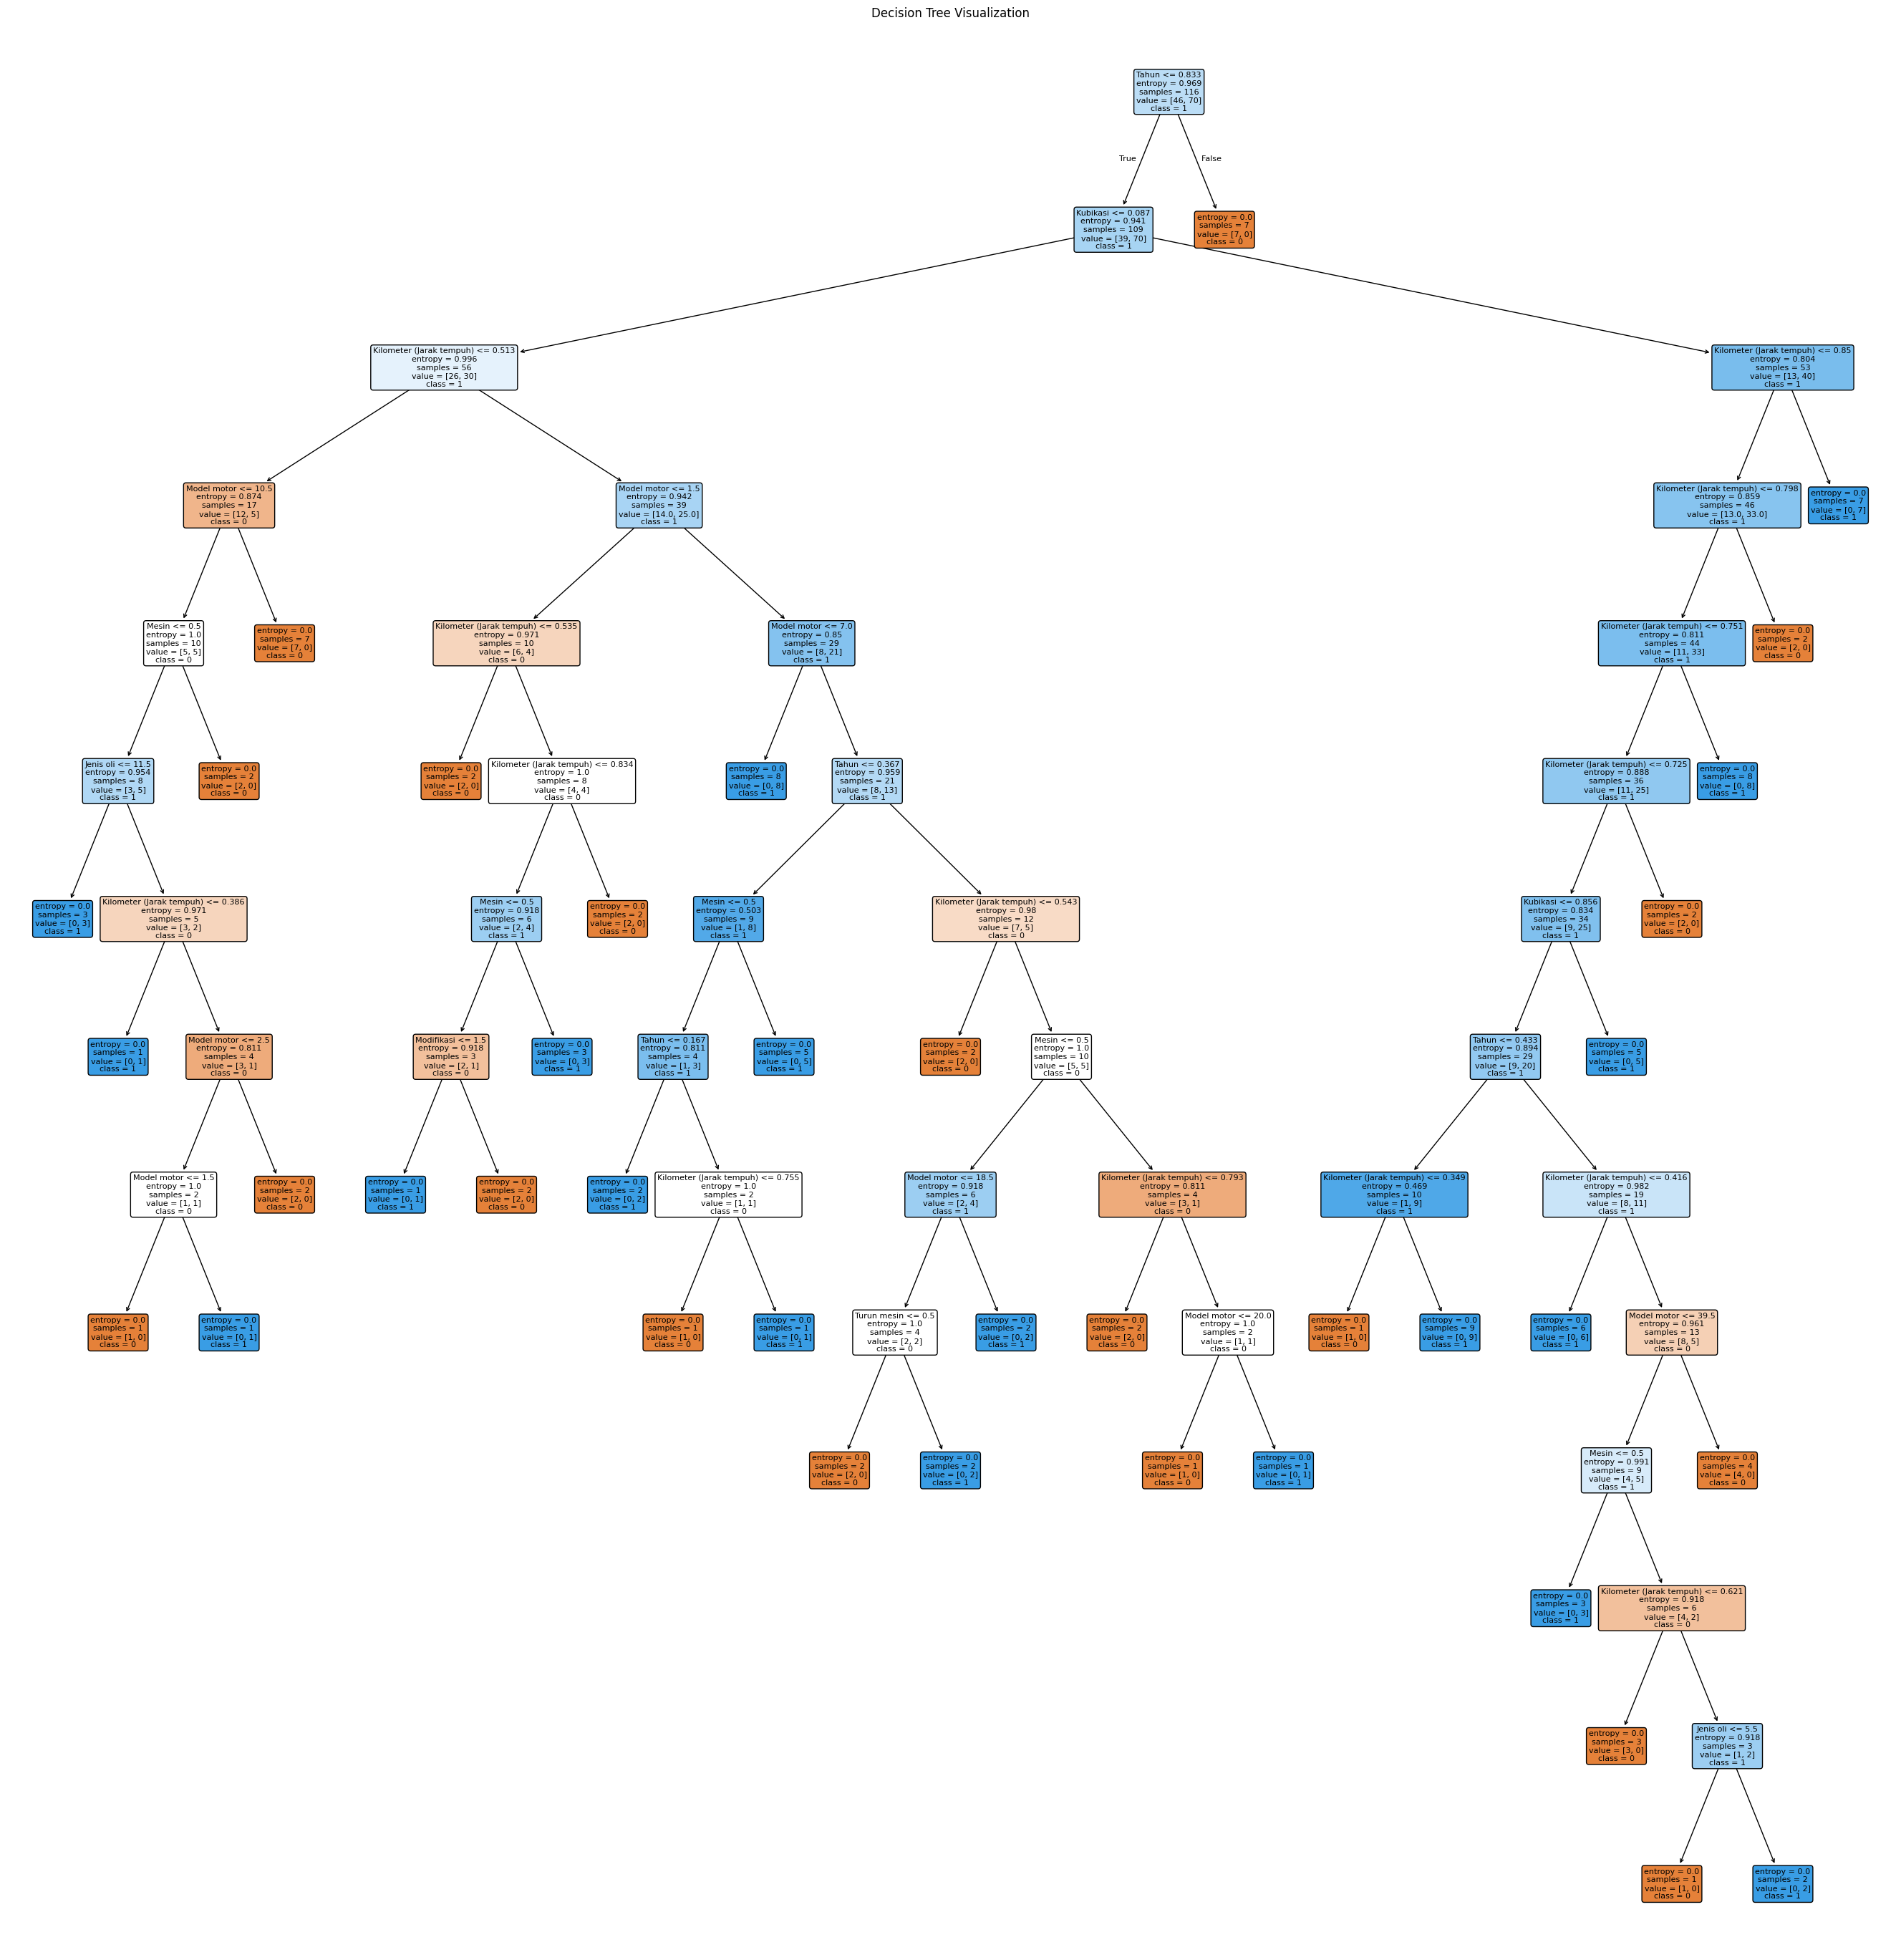

In [48]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 8️⃣ **Visualisasi Decision Tree**
plt.figure(figsize=(34, 35))  # Menentukan ukuran gambar
plot_tree(
    clf,  # Model Decision Tree yang sudah dilatih
    feature_names=X.columns,  # Nama fitur yang digunakan
    class_names=["0", "1"],  # Nama kelas (sesuaikan jika berbeda)
    filled=True,  # Mengisi warna sesuai dengan klasifikasi
    rounded=True,  # Membuat sudut lebih halus
    fontsize=8  # Ukuran font agar lebih terbaca
)
plt.title("Decision Tree Visualization")  # Judul visualisasi
plt.show()  # Menampilkan gambar


In [49]:


# Coba impor tabulate, jika tidak ada gunakan metode alternatif
try:
    from tabulate import tabulate
    use_tabulate = True
except ModuleNotFoundError:
    use_tabulate = False

# Mapping hasil prediksi ke label keputusan
decision_mapping = {0: "Tidak layak", 1: "Layak dijual"}

# Cek apakah kolom yang digunakan ada dalam X_test
print("📌 Kolom yang tersedia dalam X_test:", list(X_test.columns))

# Pilih kolom yang akan ditampilkan dalam hasil prediksi
selected_columns = [
    'Model motor', 'Tahun', 'Mesin', 'Kilometer (Jarak tempuh)',
    'Bahan Bakar', 'Modifikasi', 'Turun mesin', 'Jenis oli',
    'Tranmisi', 'Jenis mesin', 'Kubikasi'
]

# Pastikan hanya kolom yang ada dalam X_test yang digunakan
existing_columns = [col for col in selected_columns if col in X_test.columns]

# Jika ada kolom yang hilang, beri peringatan
missing_columns = set(selected_columns) - set(existing_columns)
if missing_columns:
    print(f"⚠️ Beberapa kolom tidak ditemukan dalam X_test: {missing_columns}")

# Buat DataFrame hasil prediksi
hasil_prediksi = X_test[existing_columns].copy()

# Pastikan indeks y_pred cocok dengan X_test
y_pred_series = pd.Series(y_pred, index=X_test.index)

# Tambahkan hasil aktual dan prediksi
hasil_prediksi["Actual"] = y_test.map(decision_mapping)
hasil_prediksi["Predicted"] = y_pred_series.map(decision_mapping)

# Pastikan tidak ada nilai NaN di kolom Predicted
hasil_prediksi["Predicted"].fillna("❌ Error pada prediksi", inplace=True)

# Menampilkan hasil dengan format yang lebih menarik
print("\n📌 Hasil Perbandingan Prediksi vs Aktual:\n")

if use_tabulate:
    print(tabulate(hasil_prediksi.head(10), headers="keys", tablefmt="fancy_grid"))
else:
    print(hasil_prediksi.head(10).T.to_string())  # Transpose jika tabulate tidak tersedia


📌 Kolom yang tersedia dalam X_test: ['Model motor', 'Tahun', 'Mesin', 'Kilometer (Jarak tempuh)', 'Bahan Bakar', 'Modifikasi', 'Turun mesin', 'Jenis oli', 'Tranmisi', 'Jenis mesin', 'Kubikasi']

📌 Hasil Perbandingan Prediksi vs Aktual:

╒═════╤═══════════════╤══════════╤═════════╤════════════════════════════╤═══════════════╤══════════════╤═══════════════╤═════════════╤════════════╤═══════════════╤════════════╤══════════════╤══════════════╕
│     │   Model motor │    Tahun │   Mesin │   Kilometer (Jarak tempuh) │   Bahan Bakar │   Modifikasi │   Turun mesin │   Jenis oli │   Tranmisi │   Jenis mesin │   Kubikasi │ Actual       │ Predicted    │
╞═════╪═══════════════╪══════════╪═════════╪════════════════════════════╪═══════════════╪══════════════╪═══════════════╪═════════════╪════════════╪═══════════════╪════════════╪══════════════╪══════════════╡
│  69 │            45 │ 0.733333 │       1 │                   0.386078 │             1 │            2 │             0 │           8 │        

<ipython-input-49-950666aa8d59>:40: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  hasil_prediksi["Predicted"].fillna("❌ Error pada prediksi", inplace=True)


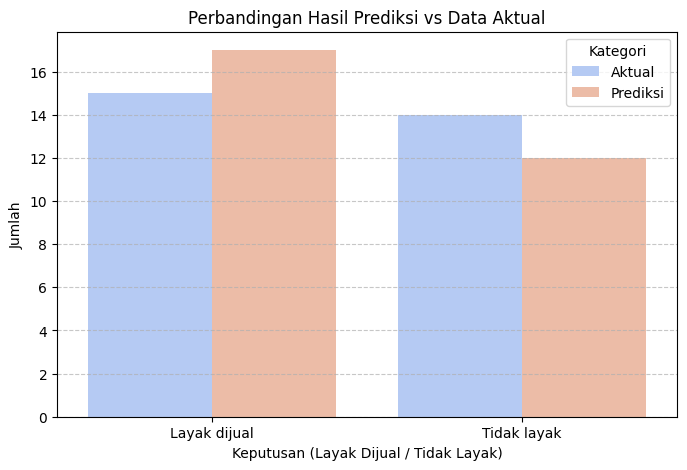

In [50]:


# Mapping hasil prediksi ke label keputusan
decision_mapping = {0: "Tidak layak", 1: "Layak dijual"}

# Konversi y_test dan y_pred ke DataFrame
hasil_prediksi = pd.DataFrame({
    "Actual": y_test.map(decision_mapping),
    "Predicted": pd.Series(y_pred, index=y_test.index).map(decision_mapping)
})

# Hitung jumlah masing-masing kategori
counts = hasil_prediksi.melt(var_name="Tipe", value_name="Keputusan")

# Buat visualisasi bar chart
plt.figure(figsize=(8, 5))
sns.countplot(x="Keputusan", hue="Tipe", data=counts, palette="coolwarm")
plt.title("Perbandingan Hasil Prediksi vs Data Aktual")
plt.xlabel("Keputusan (Layak Dijual / Tidak Layak)")
plt.ylabel("Jumlah")
plt.legend(title="Kategori", labels=["Aktual", "Prediksi"])
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Tampilkan grafik
plt.show()
